**Process of training about data scientist, using LINEAR REGRESSION**

**Data Understanding**

In [1]:
import pandas as pd

df = pd.read_csv("placement.csv")

df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


In [2]:
df.describe()

,cgpa,placement_exam_marks,placed
count,1000.000000,1000.000000,1000.000000
mean,6.961240,32.225000,0.489000
std,0.615898,19.130822,0.500129
min,4.890000,0.000000,0.000000
25%,6.550000,17.000000,0.000000
50%,6.960000,28.000000,0.000000
75%,7.370000,44.000000,1.000000
max,9.120000,100.000000,1.000000


In [3]:
df.iloc[1:20]

,cgpa,placement_exam_marks,placed
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
5,7.30,23.0,1
6,6.69,11.0,0
7,7.12,39.0,1
8,6.45,38.0,0
9,7.75,94.0,1
10,6.82,16.0,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   cgpa                  1000 non-null   float64
 1   placement_exam_marks  1000 non-null   float64
 2   placed                1000 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 23.6 KB


**Data Cleaning & Preparation**

In [5]:
df = df.drop_duplicates()

In [6]:
# Menampilkan nilai True jika data kosong
df.isna()

,cgpa,placement_exam_marks,placed
0,False,False,False
1,False,False,False
2,False,False,False
3,False,False,False
4,False,False,False
...,...,...,...
995,False,False,False
996,False,False,False
997,False,False,False
998,False,False,False


In [7]:
df.isna().sum()

cgpa                    0
placement_exam_marks    0
placed                  0
dtype: int64

In [8]:
# Mengecek korelasi data
matrix = df.corr()
print("Matrix Korelasi Data:")
print(matrix)

Matrix Korelasi Data:
                          cgpa  placement_exam_marks    placed
cgpa                  1.000000             -0.031832  0.026767
placement_exam_marks -0.031832              1.000000 -0.023415
placed                0.026767             -0.023415  1.000000


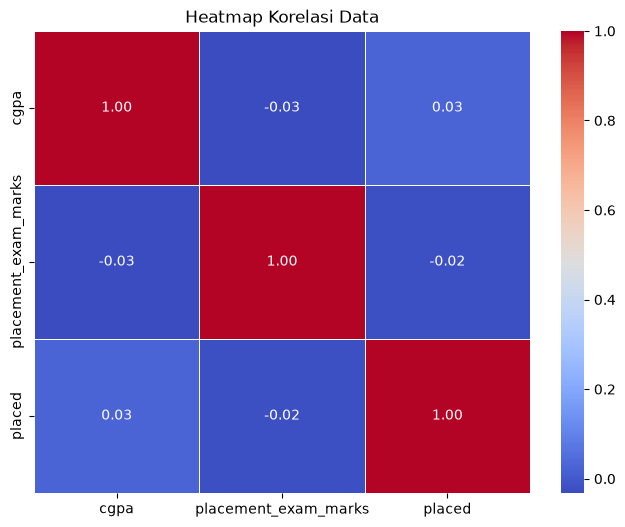

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Heatmap Korelasi Data")
plt.show()

**Mengecek Outlier**

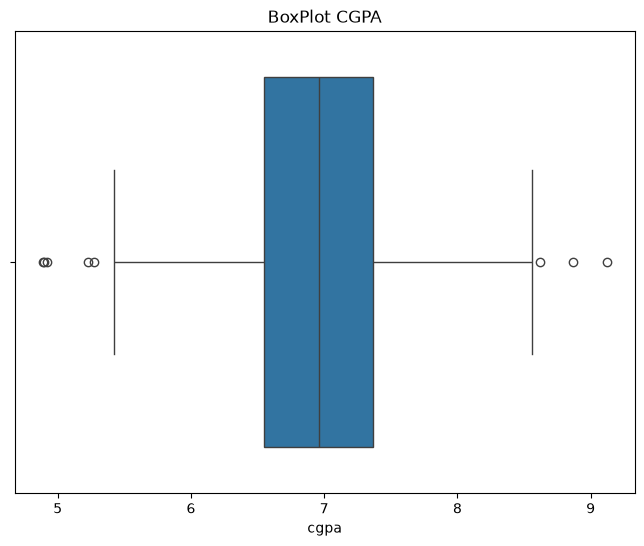

In [10]:
plt.figure(figsize=(8,6))
sns.boxplot(x=df["cgpa"])
plt.title("BoxPlot CGPA")
plt.show()

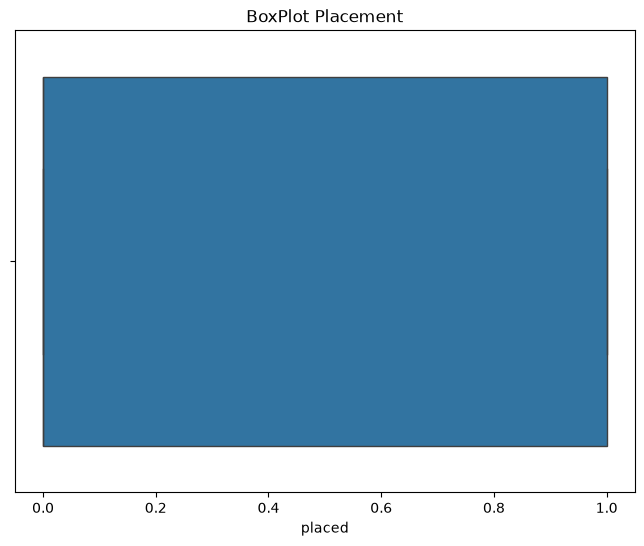

In [11]:
plt.figure(figsize=(8,6))
sns.boxplot(x=df["placed"])
plt.title("BoxPlot Placement")
plt.show()

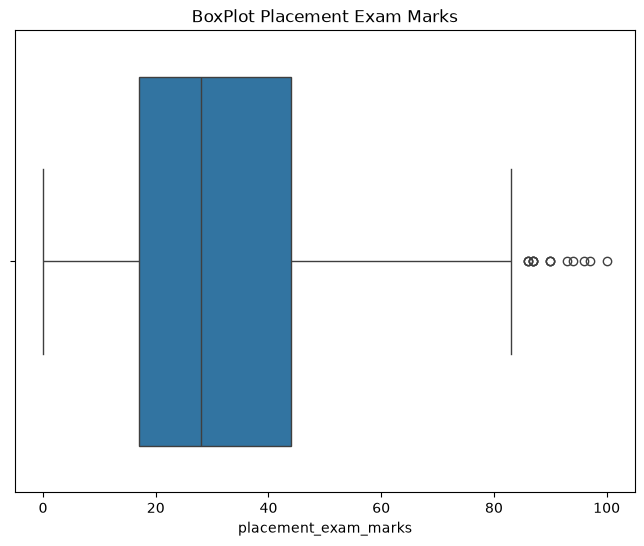

In [12]:
plt.figure(figsize=(8,6))
sns.boxplot(x=df["placement_exam_marks"])
plt.title("BoxPlot Placement Exam Marks")
plt.show()

In [13]:
df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


<Axes: xlabel='cgpa', ylabel='Percent'>

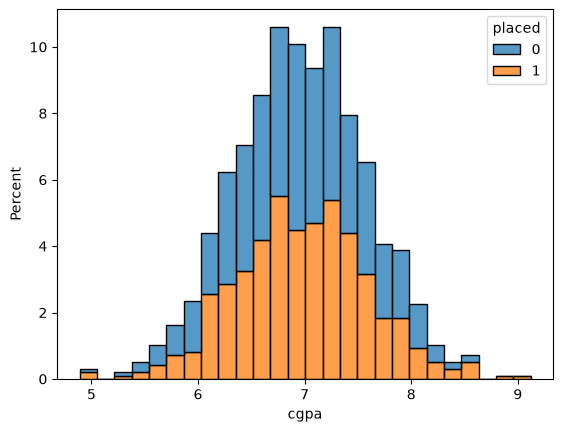

In [25]:
sns.histplot(data = df, x = "cgpa", hue = "placed", stat = "percent", multiple = "stack")

<Axes: xlabel='cgpa', ylabel='placement_exam_marks'>

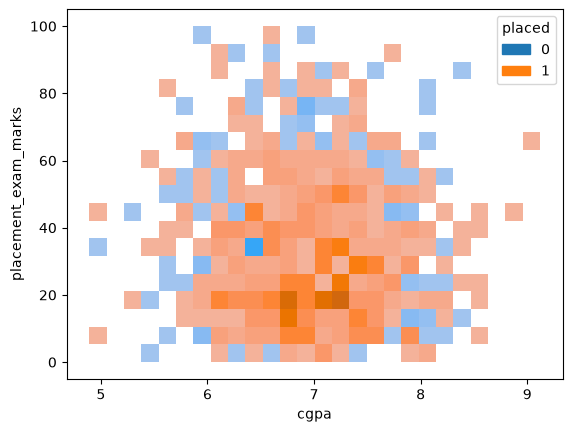

In [37]:
sns.histplot(data = df, x = "cgpa", y = "placement_exam_marks", hue = "placed")

<Axes: xlabel='cgpa', ylabel='placement_exam_marks'>

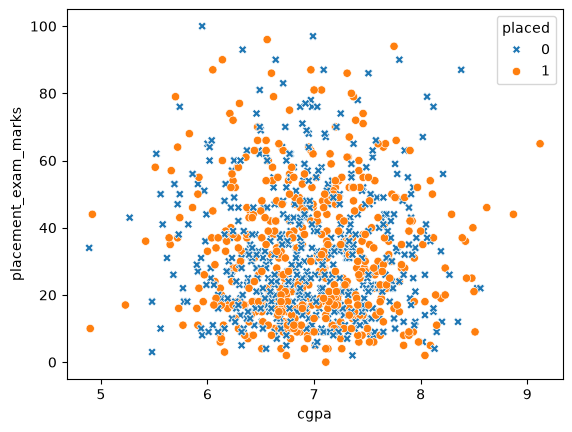

In [46]:
markers = {1: "o", 0: "X" }
sns.scatterplot(data = df, x = "cgpa", y = "placement_exam_marks", hue = "placed", style = "placed", markers = markers)

**Model Training**

In [48]:
df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


In [49]:
X = df["cgpa"]
y = df["placement_exam_marks"]

In [50]:
from sklearn.model_selection import train_test_split



X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 42)

In [51]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [53]:
model.fit(pd.DataFrame(X_train), y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.13]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['cgpa']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,33.26
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [54]:
y_pred = model.predict(pd.DataFrame(X_test))

In [ ]:
# Menghitung perkiraan placement_exam_marks
predict_cgpa = np.array([8])

for 